In [2]:
#Import Libraries
import pandas as pd
import seaborn as sns
import numpy as np

import matplotlib
import matplotlib.pyplot as plt
plt.style.use('ggplot') #Apply ggplot visual theme
from matplotlib.pyplot import figure

#to show plots below code:
%matplotlib inline 
matplotlib.rcParams['figure.figsize'] =(12,8) #to set default plot size

#Read data
df= pd.read_csv(r"C:\analytics\python_movie_project\movies.csv")


In [24]:
#To see the data
df.head()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000,46998772,Warner Bros.,146
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000,58853106,Columbia Pictures,104
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000.0,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000,538375067,Lucasfilm,124
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000.0,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000,83453539,Paramount Pictures,88
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000.0,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000,39846344,Orion Pictures,98


In [9]:
#Data Cleaning
#to check missing data
for col in df.columns:
     pct_missing= np.mean(df[col].isnull())
     print(f"{col}->{pct_missing*100:.2f}%")

name->0.00%
rating->1.00%
genre->0.00%
year->0.00%
released->0.03%
score->0.04%
votes->0.04%
director->0.00%
writer->0.04%
star->0.01%
country->0.04%
budget->28.31%
gross->2.46%
company->0.22%
runtime->0.05%


In [10]:
#Dropping missing values for better analysis
initial_rows=len(df)
df.dropna(subset=['budget','gross'],inplace=True)
final_rows=len(df)
print(f"Out of {initial_rows}, {initial_rows-final_rows} rows have been deleted.")

Out of 7668, 2232 rows have been deleted.


In [23]:
#Checking data types for columns
df.dtypes

name            str
rating          str
genre           str
year          int64
released        str
score       float64
votes       float64
director        str
writer          str
star            str
country         str
budget        Int64
gross         Int64
company         str
runtime       Int64
dtype: object

In [11]:
#Formatting

#Removing unnecessary .0's from budget, gross, votes and runtime columns
df['budget']=df['budget'].astype('Int64')
df['gross']=df['gross'].astype('Int64')
df['runtime']=df['runtime'].astype('Int64')
df['votes']=df['votes'].astype('Int64')

In [27]:
#Consistency check

#Checking 'year' and 'released' columns for inconsistencies
df['released_year']=df['released'].str.extract(r'(\d{4})')
df['released_year']=pd.to_numeric(df['released_year'],errors='coerce')
mismatched_rows=df[df['year'] != df['released_year']]
print(f"Number of inconsistent rows: {len(mismatched_rows)}")

Number of inconsistent rows: 713


In [29]:
# Examining inconsistent rows
display(mismatched_rows[['name', 'year', 'released', 'released_year']].head(10))

,name,year,released,released_year
8,Superman II,1980,"June 19, 1981 (United States)",1981
11,The Gods Must Be Crazy,1980,"October 26, 1984 (United States)",1984
21,Heaven's Gate,1980,"April 24, 1981 (United States)",1981
33,Cattle Annie and Little Britches,1980,"April 24, 1981 (United States)",1981
96,The Evil Dead,1981,"April 15, 1983 (United States)",1983
97,Porky's,1981,"March 19, 1982 (United States)",1982
101,Mad Max 2,1981,"May 21, 1982 (United States)",1982
118,Chariots of Fire,1981,"April 9, 1982 (United States)",1982
129,Cutter's Way,1981,"February 10, 1982 (France)",1982
130,Quest for Fire,1981,"February 12, 1982 (United States)",1982


In [22]:
df.sort_values(by=['gross'],inplace=False,ascending=False)
df.head(10)

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000,46998772,Warner Bros.,146
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000,58853106,Columbia Pictures,104
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000,538375067,Lucasfilm,124
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000,83453539,Paramount Pictures,88
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000,39846344,Orion Pictures,98
5,Friday the 13th,R,Horror,1980,"May 9, 1980 (United States)",6.4,123000,Sean S. Cunningham,Victor Miller,Betsy Palmer,United States,550000,39754601,Paramount Pictures,95
6,The Blues Brothers,R,Action,1980,"June 20, 1980 (United States)",7.9,188000,John Landis,Dan Aykroyd,John Belushi,United States,27000000,115229890,Universal Pictures,133
7,Raging Bull,R,Biography,1980,"December 19, 1980 (United States)",8.2,330000,Martin Scorsese,Jake LaMotta,Robert De Niro,United States,18000000,23402427,Chartoff-Winkler Productions,129
8,Superman II,PG,Action,1980,"June 19, 1981 (United States)",6.8,101000,Richard Lester,Jerry Siegel,Gene Hackman,United States,54000000,108185706,Dovemead Films,127
9,The Long Riders,R,Biography,1980,"May 16, 1980 (United States)",7.0,10000,Walter Hill,Bill Bryden,David Carradine,United States,10000000,15795189,United Artists,100


In [12]:
#to check and drop duplicates
duplicate_count=df.duplicated().sum()
print(f"Number of duplicate rows:{duplicate_count}")

Number of duplicate rows:0


Correlation coefficient is 0.74


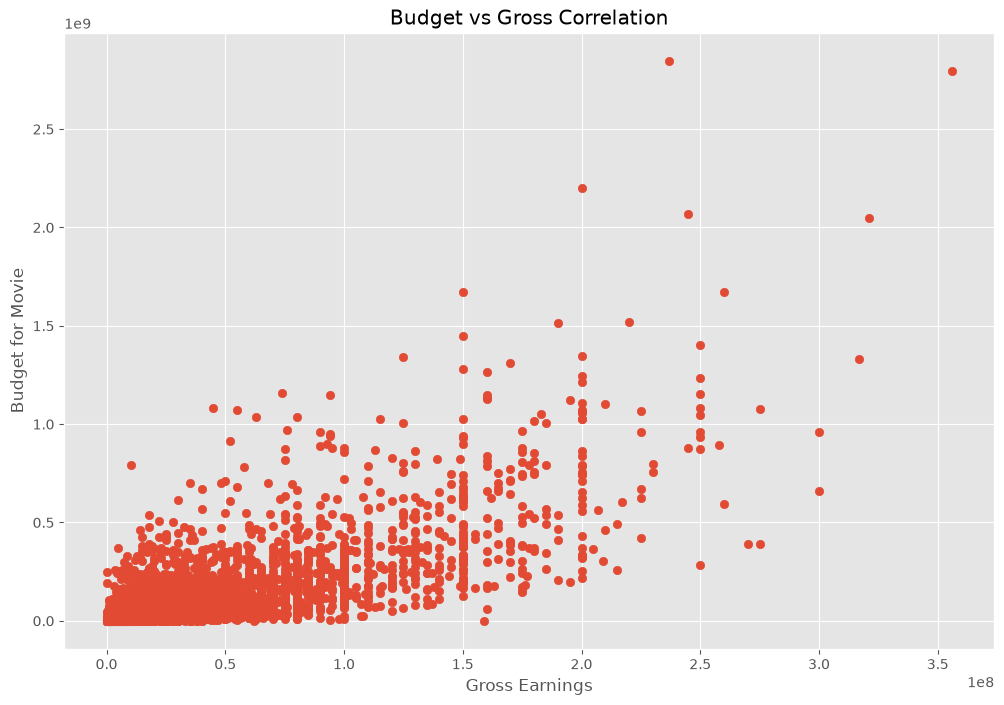

In [13]:
#Data Analysis

#Correlation check
correlation=df['budget'].corr(df['gross'])
print(f"Correlation coefficient is {correlation:.2f}")
#Scatter plot with budget and gross
plt.scatter(x=df['budget'],y=df['gross'])
plt.title('Budget vs Gross Correlation')
plt.xlabel('Gross Earnings')
plt.ylabel('Budget for Movie')
plt.show()

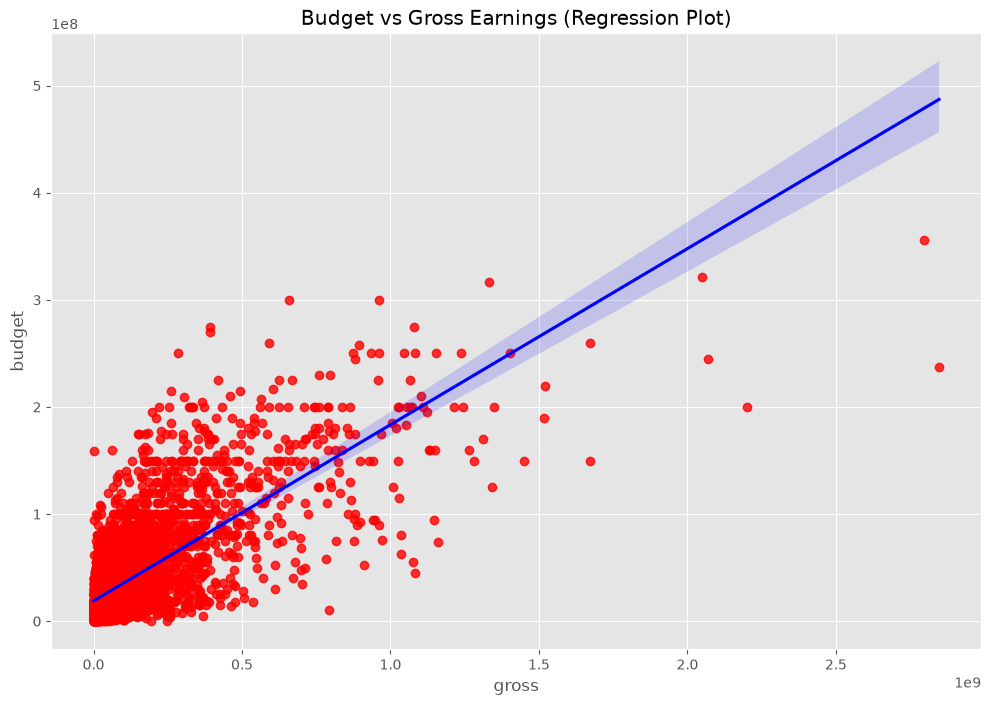

In [17]:
#Regression plot to see the correlation better
sns.regplot(x='gross',y='budget',data=df,scatter_kws={'color':'red'},line_kws={'color':'blue'})
plt.title("Budget vs Gross Earnings (Regression Plot)")
plt.show()

C:\Users\Elena Işıl\AppData\Local\Temp\ipykernel_16520\433207698.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_companies.values, y=top_companies.index, palette='viridis')


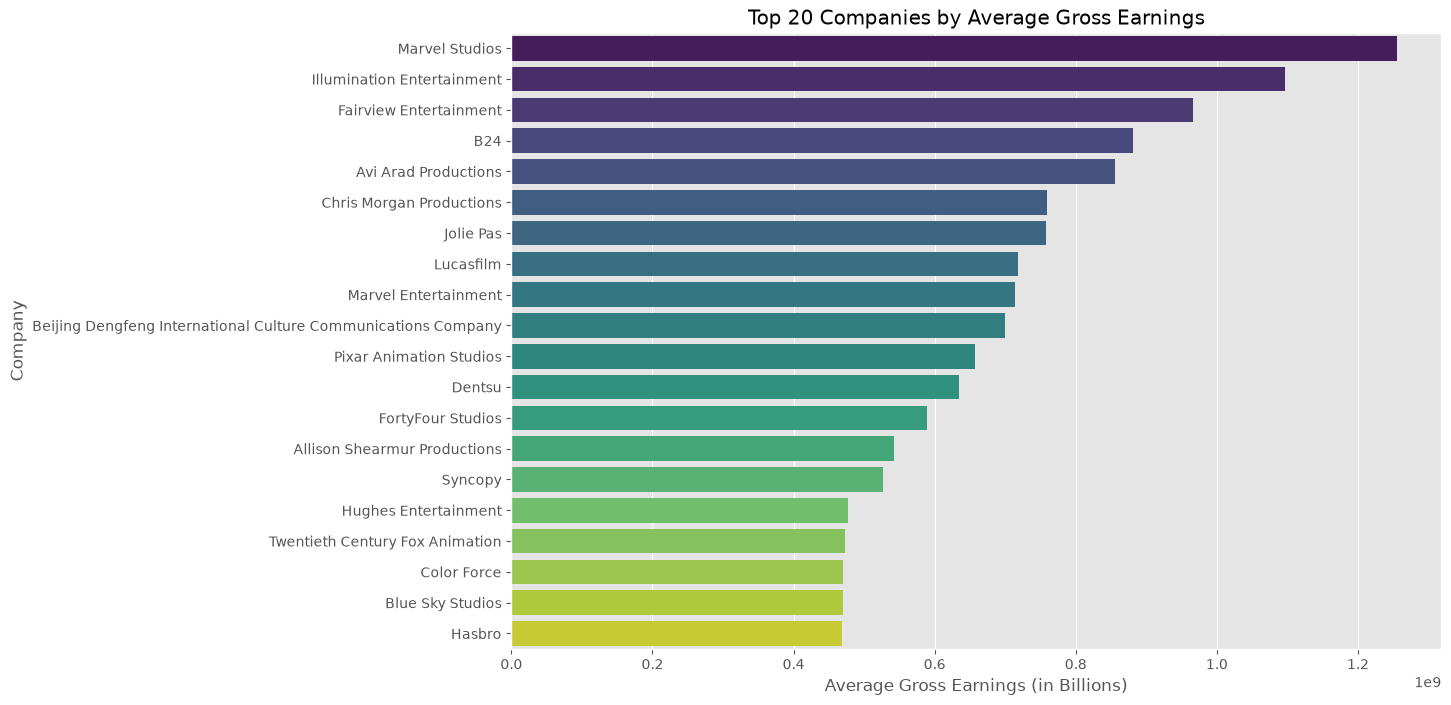

In [21]:
#Top companies by average gross using bar chart
top_companies=df.groupby('company')['gross'].mean().sort_values(ascending=False).head(20)
sns.barplot(x=top_companies.values, y=top_companies.index, palette='viridis')
plt.title('Top 20 Companies by Average Gross Earnings')
plt.xlabel('Average Gross Earnings (in Billions)')
plt.ylabel('Company')
plt.show()